# 📊 Biais et approfondissement

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 14h15** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Détecter les sur- et sous-représentations par rapport à une référence
- Quantifier les disparités d'une décision algorithmique avec Fairlearn
- Identifier les corrélations induites et les limites de l'analyse

**Maison Lumen — Soualiho KAMAGATÉ et Julien FOURNIER**

In [1]:
import os, sys, subprocess, importlib.util
for paquet in ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "statsmodels", "fairlearn", "gdown"]:
    if importlib.util.find_spec(paquet) is None:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",paquet])
CONFIG_ID="1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"
if not os.path.exists("config_projet.py"):
    import gdown
    gdown.download(id=CONFIG_ID,output="config_projet.py",quiet=True)
print("✅ Configuration prête")

In [2]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")
from pathlib import Path
from IPython.display import display, Markdown
evenement=pd.Timestamp(cfg["evenement"][0])
sensibles=cfg["sensibles"]


Maison Lumen · 24224 lignes, 16 colonnes


In [3]:
from fairlearn.metrics import (MetricFrame, selection_rate, count, true_positive_rate,
                               demographic_parity_difference, demographic_parity_ratio)
df = nettoyage_minimal(brut, cfg)
for col in cfg["sensibles"]:
    df[col] = df[col].fillna("inconnu")
y = df[cfg["decision"]]
print("Décision étudiée :", cfg["decision_label"], f"· taux global {y.mean():.1%}")
df=nettoyage_minimal(brut,cfg)
df["region"]=df.region.fillna("inconnu")
df["apres"]=df.date_commande.ge(evenement).astype(int)
df["periode"]=np.where(df.apres.eq(1),"Après refonte","Avant refonte")
print(len(brut),"→",len(df),"; lignes retirées :",len(brut)-len(df))
print("Doublons exacts :",brut.duplicated().sum(),"; avoirs négatifs après dédoublonnage :",brut.drop_duplicates().montant_eur.lt(0).sum())

Décision étudiée : offre personnalisée envoyée · taux global 40.6%
24224 → 24089 ; lignes retirées : 135
Doublons exacts : 121 ; avoirs négatifs après dédoublonnage : 14


## 1. La représentativité
Sur les **clients uniques**, comparez la part de chaque modalité à la population de référence (`reference()`). Signalez les ratios inférieurs à 0,8 ou supérieurs à 1,25.

In [4]:
clients=df.sort_values("date_commande").drop_duplicates("client_id")
p_ref=Path("data/reference_population.csv")
if not p_ref.exists():
    from google.colab import files
    files.upload()
ref=pd.read_csv(p_ref)
representativite=[]
for col in sensibles:
    obs=clients[col].value_counts(normalize=True).rename("part_observee")
    r=ref.loc[ref.variable.eq(col)].set_index("modalite").join(obs)
    r["ratio"]=r.part_observee/r.part_reference
    r["signal"]=np.where(r.ratio.lt(.8),"sous-représenté",np.where(r.ratio.gt(1.25),"surreprésenté","dans les seuils"))
    display(r)
    representativite.append(r.reset_index())
representativite=pd.concat(representativite,ignore_index=True)
signaux=representativite.loc[representativite.ratio.lt(.8)|representativite.ratio.gt(1.25)]
texte=" ; ".join(f"{r.modalite} : {r.ratio:.2f}" for r in signaux.itertuples())
display(Markdown("Les groupes qui dépassent les seuils sont : **"+texte+"**. Ces ratios décrivent la clientèle présente, pas tous les prospects. La région inconnue n’a pas de catégorie de référence ; sa part est conservée dans le dénominateur, sans lui attribuer un ratio artificiel."))

,variable,part_reference,part_observee,ratio,signal
modalite,,,,,
18-24,tranche_age,0.10,0.138889,1.388889,surreprésenté
25-34,tranche_age,0.15,0.295065,1.967100,surreprésenté
35-44,tranche_age,0.16,0.252807,1.580046,surreprésenté
45-54,tranche_age,0.17,0.164007,0.964748,dans les seuils
55-64,tranche_age,0.16,0.087175,0.544843,sous-représenté
65+,tranche_age,0.26,0.062057,0.238680,sous-représenté


,variable,part_reference,part_observee,ratio,signal
modalite,,,,,
F,genre,0.52,0.62367,1.199366,dans les seuils
H,genre,0.48,0.37633,0.784020,sous-représenté


,variable,part_reference,part_observee,ratio,signal
modalite,,,,,
Île-de-France,region,0.19,0.309545,1.629184,surreprésenté
Nord-Est,region,0.24,0.168144,0.700601,sous-représenté
Ouest,region,0.21,0.173907,0.828127,dans les seuils
Sud-Ouest,region,0.14,0.116135,0.829534,dans les seuils
Sud-Est,region,0.19,0.206708,1.087937,dans les seuils
Outre-mer,region,0.03,0.014923,0.497439,sous-représenté


Les groupes qui dépassent les seuils sont : **18-24 : 1.39 ; 25-34 : 1.97 ; 35-44 : 1.58 ; 55-64 : 0.54 ; 65+ : 0.24 ; H : 0.78 ; Île-de-France : 1.63 ; Nord-Est : 0.70 ; Outre-mer : 0.50**. Ces ratios décrivent la clientèle présente, pas tous les prospects. La région inconnue n’a pas de catégorie de référence ; sa part est conservée dans le dénominateur, sans lui attribuer un ratio artificiel.

## 2. La parité de la décision
Pour chaque variable sensible, calculez avec `MetricFrame` le taux de décision favorable et l'effectif par groupe, puis l'écart et le ratio de parité démographique.

,taux,n
tranche_age,,
18-24,0.477915,3396.0
25-34,0.483785,7123.0
35-44,0.384951,5954.0
45-54,0.401703,4110.0
55-64,0.247549,2040.0
65+,0.173943,1466.0


,taux,n
genre,,
F,0.420589,15105.0
H,0.380565,8984.0


,taux,n
region,,
Nord-Est,0.403491,4010.0
Ouest,0.405405,4292.0
Outre-mer,0.254958,353.0
Sud-Est,0.404418,4844.0
Sud-Ouest,0.412082,2781.0
inconnu,0.348739,238.0
Île-de-France,0.414212,7571.0


,variable,ecart,ratio
0,tranche_age,0.309842,0.359546
1,genre,0.040024,0.904839
2,region,0.159255,0.615524


L’écart relatif le plus marqué concerne **tranche_age**. Les taux vont de **17.4%** (65+) à **48.4%** (25-34). C’est un point à examiner ; ce tableau ne dit pas encore ce qui produit l’écart.

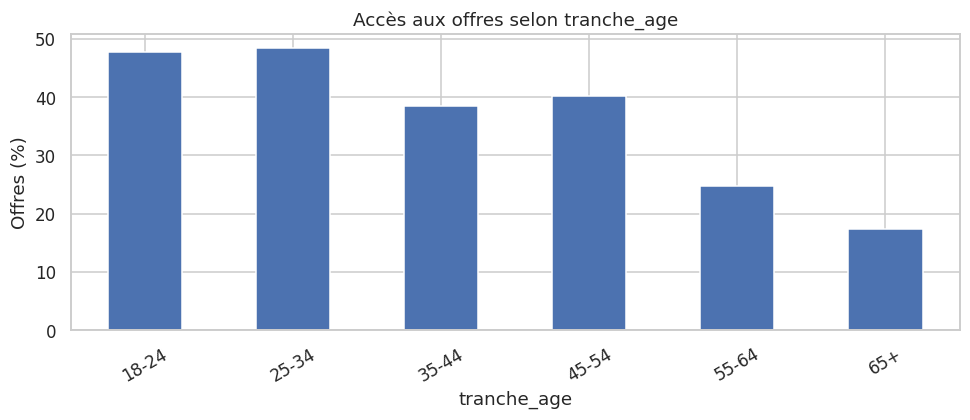

In [5]:
synthese=[]
for col in sensibles:
    mf=MetricFrame(metrics={"taux":selection_rate,"n":count},y_true=df.rachat_90j,y_pred=y,sensitive_features=df[col])
    display(mf.by_group)
    synthese.append({"variable":col,"ecart":demographic_parity_difference(df.rachat_90j,y,sensitive_features=df[col]),"ratio":demographic_parity_ratio(df.rachat_90j,y,sensitive_features=df[col])})
synthese=pd.DataFrame(synthese)
display(synthese)
var=synthese.sort_values("ratio").variable.iloc[0]
taux=df.groupby(var).offre_personnalisee.mean()
display(Markdown(f"L’écart relatif le plus marqué concerne **{var}**. Les taux vont de **{taux.min():.1%}** ({taux.idxmin()}) à **{taux.max():.1%}** ({taux.idxmax()}). C’est un point à examiner ; ce tableau ne dit pas encore ce qui produit l’écart."))
ax=taux.mul(100).plot.bar(rot=30,figsize=(9,4));ax.set(ylabel="Offres (%)",title=f"Accès aux offres selon {var}")
plt.tight_layout();plt.show()

## 3. Les croisements
Un biais peut se cacher dans un croisement. Calculez le taux par combinaison de deux variables sensibles.

In [6]:
mf2=MetricFrame(metrics={"taux":selection_rate,"n":count},y_true=df.rachat_90j,y_pred=y,sensitive_features=df[["genre","tranche_age"]])
display(mf2.by_group)
print("Groupes de moins de 30 commandes :")
display(mf2.by_group.loc[mf2.by_group["n"]<30])
croises=mf2.by_group
fiables=croises.loc[croises["n"].ge(30)]
display(Markdown(f"Parmi les croisements d’au moins 30 commandes, les taux vont de **{fiables.taux.min():.1%}** à **{fiables.taux.max():.1%}**. Le groupe le moins servi est **{fiables.taux.idxmin()}**. Je regarde aussi son effectif avant d’en tirer une conclusion : un taux isolé ne suffit pas à décrire tous les clients du groupe."))


taux       n
genre tranche_age                  
F     18-24        0.497501  2201.0
      25-34        0.496067  4449.0
      35-44        0.400054  3697.0
      45-54        0.414898  2497.0
      55-64        0.271429  1330.0
      65+          0.187970   931.0
H     18-24        0.441841  1195.0
      25-34        0.463351  2674.0
      35-44        0.360213  2257.0
      45-54        0.381277  1613.0
      55-64        0.202817   710.0
      65+          0.149533   535.0

,,taux,n
genre,tranche_age,,


Parmi les croisements d’au moins 30 commandes, les taux vont de **15.0%** à **49.8%**. Le groupe le moins servi est **('H', '65+')**. Je regarde aussi son effectif avant d’en tirer une conclusion : un taux isolé ne suffit pas à décrire tous les clients du groupe.

Groupes de moins de 30 commandes :


## 4. Les corrélations induites
La disparité la plus forte persiste-t-elle **à segment égal** ? Comparez les taux par variable sensible à l'intérieur de chaque segment métier.

In [7]:
detail=df.groupby(["canal",var]).offre_personnalisee.agg(taux="mean",n="size")
display(detail)
poids=df.canal.value_counts(normalize=True)
standard=detail.taux.unstack(0).reindex(columns=poids.index)
standard["Taux standardisé"]=standard.mul(poids,axis=1).sum(axis=1,min_count=len(poids))
display(standard)
ecart_brut=taux.max()-taux.min()
ecart_std=standard["Taux standardisé"].max()-standard["Taux standardisé"].min()
display(Markdown(f"Avec la même répartition des canaux pour tous les groupes, l’écart passe de **{ecart_brut*100:.1f}** à **{ecart_std*100:.1f} points**. {'Une partie de l’écart est compatible avec une différence de fréquentation des canaux ; un écart reste visible à canal comparable.' if ecart_std<ecart_brut else 'Le contrôle du canal ne réduit pas l’écart observé.'} Ce calcul ne contrôle pas les autres différences de clientèle."))

taux     n
canal   tranche_age                
app     18-24        0.518428   407
        25-34        0.521277   846
        35-44        0.424695   737
        45-54        0.443750   480
        55-64        0.347518   141
        65+          0.242105    95
magasin 18-24        0.460405  1629
        25-34        0.448327  3348
        35-44        0.350421  2731
        45-54        0.354015  1918
        55-64        0.224446  1399
        65+          0.138298  1034
web     18-24        0.486765  1360
        25-34        0.513486  2929
        35-44        0.411102  2486
        45-54        0.443341  1712
        55-64        0.284000   500
        65+          0.264095   337

canal,magasin,web,app,Taux standardisé
tranche_age,,,,
18-24,0.460405,0.486765,0.518428,0.477126
25-34,0.448327,0.513486,0.521277,0.481743
35-44,0.350421,0.411102,0.424695,0.382252
45-54,0.354015,0.443341,0.443750,0.398670
55-64,0.224446,0.284000,0.347518,0.261322
65+,0.138298,0.264095,0.242105,0.198651


Avec la même répartition des canaux pour tous les groupes, l’écart passe de **31.0** à **28.3 points**. Une partie de l’écart est compatible avec une différence de fréquentation des canaux ; un écart reste visible à canal comparable. Ce calcul ne contrôle pas les autres différences de clientèle.

**Lecture** : la disparité vient-elle de la variable sensible elle-même, ou d'un proxy ?

L’écart passe de 31,0 à 28,3 points après standardisation des canaux : il reste donc important à canal comparable. Le canal ne suffit pas à rendre compte de la disparité. Ces données ne permettent pas d’isoler l’effet propre de l’âge ni d’identifier un proxy avec certitude.

## 5. L'évolution dans le temps
La disparité a-t-elle changé avec l'événement du brief ? Comparez les taux avant et après la date.

In [8]:
evol=df.groupby(["periode",var]).offre_personnalisee.agg(taux="mean",n="size")
display(evol)
e=evol.taux.unstack(0).reindex(columns=["Avant refonte","Après refonte"])
e["Variation (points)"]=(e.iloc[:,1]-e.iloc[:,0])*100
display(e)
for periode,g in df.groupby("periode"):
    d=demographic_parity_difference(g.rachat_90j,g.offre_personnalisee,sensitive_features=g[var])
    print(f"{periode} : écart max-min = {d*100:.1f} points")
avant=e["Avant refonte"];apres=e["Après refonte"]
display(Markdown(f"L’écart entre le groupe le plus servi et le moins servi passe de **{(avant.max()-avant.min())*100:.1f}** à **{(apres.max()-apres.min())*100:.1f} points**. La refonte n’efface donc pas les écarts d’accès aux offres. Pour comprendre leur origine, il faudrait examiner les règles de ciblage et les profils des clients, au-delà du seul canal."))


taux     n
periode       tranche_age                
Après refonte 18-24        0.475676  2220
              25-34        0.488515  4571
              35-44        0.386611  3854
              45-54        0.405083  2597
              55-64        0.256950  1331
              65+          0.179296   937
Avant refonte 18-24        0.482143  1176
              25-34        0.475313  2552
              35-44        0.381905  2100
              45-54        0.395902  1513
              55-64        0.229901   709
              65+          0.164461   529

periode,Avant refonte,Après refonte,Variation (points)
tranche_age,,,
18-24,0.482143,0.475676,-0.646718
25-34,0.475313,0.488515,1.320107
35-44,0.381905,0.386611,0.470655
45-54,0.395902,0.405083,0.918061
55-64,0.229901,0.256950,2.704839
65+,0.164461,0.179296,1.483438


L’écart entre le groupe le plus servi et le moins servi passe de **31.8** à **30.9 points**. La refonte n’efface donc pas les écarts d’accès aux offres. Pour comprendre leur origine, il faudrait examiner les règles de ciblage et les profils des clients, au-delà du seul canal.

Après refonte : écart max-min = 30.9 points
Avant refonte : écart max-min = 31.8 points


## 6. L'égalité des chances
Quand le résultat réel est connu, comparez le **taux de vrais positifs** par groupe : parmi ceux pour qui le résultat a été favorable, quelle part avait reçu la décision favorable ?

In [9]:
connu=df.rachat_90j.notna() & df.offre_personnalisee.notna()
d=df.loc[connu]
mf_tpr=MetricFrame(metrics={"TPR":true_positive_rate,"n":count},y_true=d.rachat_90j,y_pred=d.offre_personnalisee,sensitive_features=d[var])
res=mf_tpr.by_group.join(d.groupby(var).rachat_90j.sum().rename("Rachats observés"))
display(res)
display(Markdown(f"Parmi les commandes suivies d’un rachat, la part ayant reçu une offre varie de **{res.TPR.min():.1%}** à **{res.TPR.max():.1%}**. C’est le sens du TPR dans cet exercice. L’offre peut elle-même influencer le rachat : ce résultat n’est donc pas une mesure d’éligibilité indépendante de la décision."))

,TPR,n,Rachats observés
tranche_age,,,
18-24,0.541241,3396.0,1273
25-34,0.553631,7123.0,2713
35-44,0.464416,5954.0,2192
45-54,0.463984,4110.0,1541
55-64,0.302511,2040.0,876
65+,0.208469,1466.0,614


Parmi les commandes suivies d’un rachat, la part ayant reçu une offre varie de **20.8%** à **55.4%**. C’est le sens du TPR dans cet exercice. L’offre peut elle-même influencer le rachat : ce résultat n’est donc pas une mesure d’éligibilité indépendante de la décision.

## 7. Les limites de l’analyse

- La référence démographique est une approximation pédagogique, qui ne correspond pas nécessairement au marché cible de Maison Lumen.
- Les taux calculés par commande donnent davantage de poids aux clients fréquents. Les métriques présentées sont descriptives, sans intervalle de confiance.
- Les régions manquantes forment le groupe « inconnu » et ne disposent pas d’une catégorie de référence.
- Le rachat à 90 jours peut dépendre de l’offre reçue. La durée effective du suivi doit aussi couvrir 90 jours.
- La comparaison à canal égal ne contrôle pas toutes les différences de profils. Les disparités observées ne suffisent pas à établir une discrimination.

## 💾 Livrable de fin de journée
Votre notebook d'analyse complet, chaque choix justifié dans une cellule markdown, enregistré dans GitHub :
*Fichier › Enregistrer une copie dans GitHub*, message « Jour 1 : analyse et biais ». Envoyez le lien du dépôt au formateur.